<a href="https://colab.research.google.com/github/faiq191/244107020214-machine-learning/blob/main/JS09/JS09_Assignment02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install annoy faiss-cpu hnswlib kaggle

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 9.3 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 32.6 MB/s  0:00:00
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520036 sha256=82255dbf9c7995ba5f4d2245cdf8b1ad8b4e1929cf32a07dbb2652bacde63696
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679797 sha256=efd7e1f15ff53d2d2dfe5d3bcd18ca1bec9d62df719fa8dec9c317856e15a4a9
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50

### Download the Dataset

In [ ]:
import os
# If you have kaggle.json in your Drive or Colab, uncomment and run:
# !mkdir -p ~/.kaggle
# !cp kaggle.json ~/.kaggle/
# !chmod 600 ~/.kaggle/kaggle.json

# Downloading the dataset
!kaggle datasets download -d bwandowando/spotify-songs-with-attributes-and-lyrics
!unzip -o spotify-songs-with-attributes-and-lyrics.zip

Dataset URL: https://www.kaggle.com/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics
License(s): CC-BY-NC-SA-4.0
100% 894M/894M [00:09<00:00, 96.5MB/s]

Archive:  spotify-songs-with-attributes-and-lyrics.zip
  inflating: songs_with_attributes_and_lyrics.csv  
  inflating: songs_with_lyrics_and_timestamps.csv  


### Preprocessing

In [ ]:
import pandas as pd
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Load dataset (using the first of the two datasets)
df = pd.read_csv('songs_with_attributes_and_lyrics.csv')
print(f"Loaded dataset with {df.shape[0]} rows and {df.shape[1]} columns.")

features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

# Drop rows with missing values in the feature columns
df_clean = df.dropna(subset=features)
X = df_clean[features].values

# Feature standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype('float32')

print(f"Preprocessed shape: {X_scaled.shape}")

Loaded dataset with 955320 rows and 17 columns.
Preprocessed shape: (955320, 9)


### Build Indexes and Benchmark Nearest Neighbor Searches

In [ ]:
k = 10
num_queries = 1000
np.random.seed(42)
query_indices = np.random.choice(len(X_scaled), size=num_queries, replace=False)
queries = X_scaled[query_indices]

# 1. Exact Nearest Neighbors (Scikit-Learn)
print("Building Exact NN index...")
exact_nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
exact_nn.fit(X_scaled)

start_time = time.time()
exact_distances, exact_indices = exact_nn.kneighbors(queries)
exact_time = time.time() - start_time
print(f"Exact NN Query Time for {num_queries} queries: {exact_time:.4f} seconds\n")

# 2. ANNOY
print("Building ANNOY index...")
f = X_scaled.shape[1]
annoy_index = AnnoyIndex(f, 'euclidean')
for i, vector in enumerate(X_scaled):
    annoy_index.add_item(i, vector)
annoy_index.build(10) # 10 trees

start_time = time.time()
annoy_indices = []
for query in queries:
    annoy_indices.append(annoy_index.get_nns_by_vector(query, k))
annoy_time = time.time() - start_time
annoy_indices = np.array(annoy_indices)

# Calculate Recall for ANNOY
annoy_recall = np.mean([len(set(exact_indices[i]).intersection(set(annoy_indices[i]))) / k for i in range(num_queries)])
print(f"ANNOY Query Time: {annoy_time:.4f} seconds, Recall: {annoy_recall:.4f}\n")

# 3. FAISS (Flat L2 index for exact, and IVF for approximate)
print("Building FAISS Index...")
faiss_index = faiss.IndexFlatL2(f)
faiss_index.add(X_scaled)

start_time = time.time()
faiss_distances, faiss_indices = faiss_index.search(queries, k)
faiss_time = time.time() - start_time
faiss_recall = np.mean([len(set(exact_indices[i]).intersection(set(faiss_indices[i]))) / k for i in range(num_queries)])
print(f"FAISS Query Time: {faiss_time:.4f} seconds, Recall: {faiss_recall:.4f}\n")

# 4. HNSWLIB
print("Building HNSWLIB Index...")
hnsw_index = hnswlib.Index(space='l2', dim=f)
hnsw_index.init_index(max_elements=len(X_scaled), ef_construction=200, M=16)
hnsw_index.add_items(X_scaled)
hnsw_index.set_ef(50)

start_time = time.time()
hnsw_indices, hnsw_distances = hnsw_index.knn_query(queries, k=k)
hnsw_time = time.time() - start_time
hnsw_recall = np.mean([len(set(exact_indices[i]).intersection(set(hnsw_indices[i]))) / k for i in range(num_queries)])
print(f"HNSWLIB Query Time: {hnsw_time:.4f} seconds, Recall: {hnsw_recall:.4f}\n")

Building Exact NN index...
Exact NN Query Time for 1000 queries: 7.1631 seconds

Building ANNOY index...
ANNOY Query Time: 0.0604 seconds, Recall: 0.8363

Building FAISS Index...
FAISS Query Time: 8.4814 seconds, Recall: 0.9981

Building HNSWLIB Index...
HNSWLIB Query Time: 0.1416 seconds, Recall: 0.9947



### Summary of Results

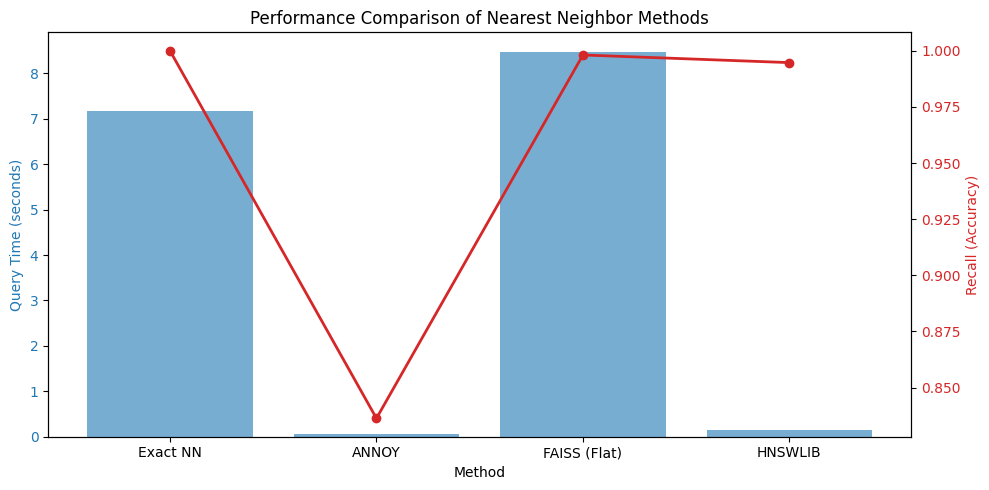

In [ ]:
import matplotlib.pyplot as plt

methods = ['Exact NN', 'ANNOY', 'FAISS (Flat)', 'HNSWLIB']
times = [exact_time, annoy_time, faiss_time, hnsw_time]
recalls = [1.0, annoy_recall, faiss_recall, hnsw_recall]

fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Method')
ax1.set_ylabel('Query Time (seconds)', color=color)
ax1.bar(methods, times, color=color, alpha=0.6, label='Query Time')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Recall (Accuracy)', color=color)
ax2.plot(methods, recalls, color=color, marker='o', linewidth=2, label='Recall')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Performance Comparison of Nearest Neighbor Methods')
fig.tight_layout()
plt.show()